# **Lab 7(A) - Laplacian Filter**

### Name: Abdullah Alnaji
### ID: 2240007157
The Laplacian is a second-order derivative that highlights rapid intensity changes (edges). Combining it with the original image gives a sharper image (sharpening).

In [8]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

## 1) Laplacian Filter with a Manual Kernel

**Important fixes to the original code:**
- `img + laplacian_abs` on `uint8` causes *overflow* (wrap-around) and produces wrong values, so we convert to `float` and `clip` to 0-255.
- A kernel with a **negative** center (-4) means the correct sharpening is `g = f - Laplacian` (not addition). With a positive-center kernel we use `g = f + Laplacian`.
- The **signed** Laplacian (before abs) is used for the combination; abs is only for display.

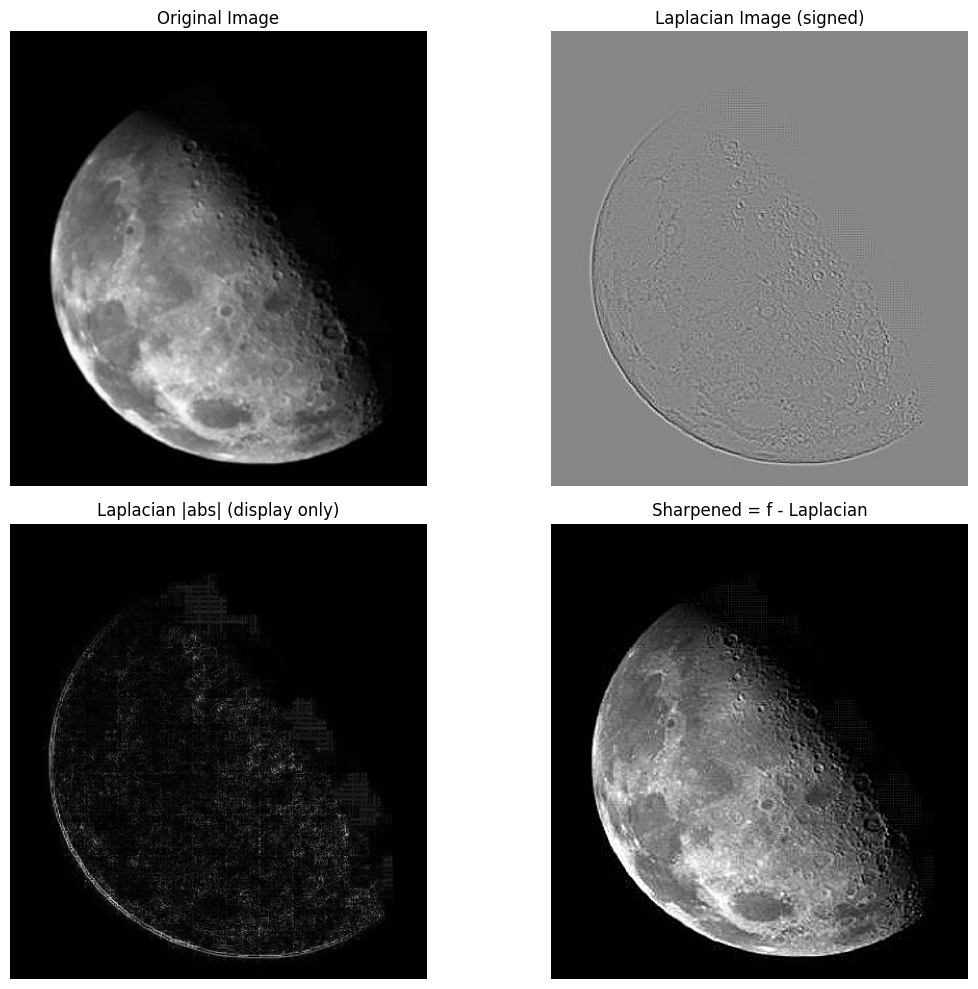

In [9]:
imgFile = "moon.jpg"
img = cv2.imread(imgFile, 0)
assert img is not None, "moon.jpg not found - upload it next to the notebook"

# Standard kernel (4-neighbors) - negative center
manual_kernel = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

# Signed Laplacian (contains negative values)
lap = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# For display only
lap_abs = cv2.convertScaleAbs(lap)

# Correct combination: negative center => subtract
sharp = np.clip(img.astype(np.float64) - lap, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image'), plt.axis('off')
plt.subplot(222), plt.imshow(lap, cmap='gray'), plt.title('Laplacian Image (signed)'), plt.axis('off')
plt.subplot(223), plt.imshow(lap_abs, cmap='gray'), plt.title('Laplacian |abs| (display only)'), plt.axis('off')
plt.subplot(224), plt.imshow(sharp, cmap='gray'), plt.title('Sharpened = f - Laplacian'), plt.axis('off')
plt.tight_layout(); plt.show()

## 2) Alternative Kernel (8-neighbors) - also detects diagonal edges

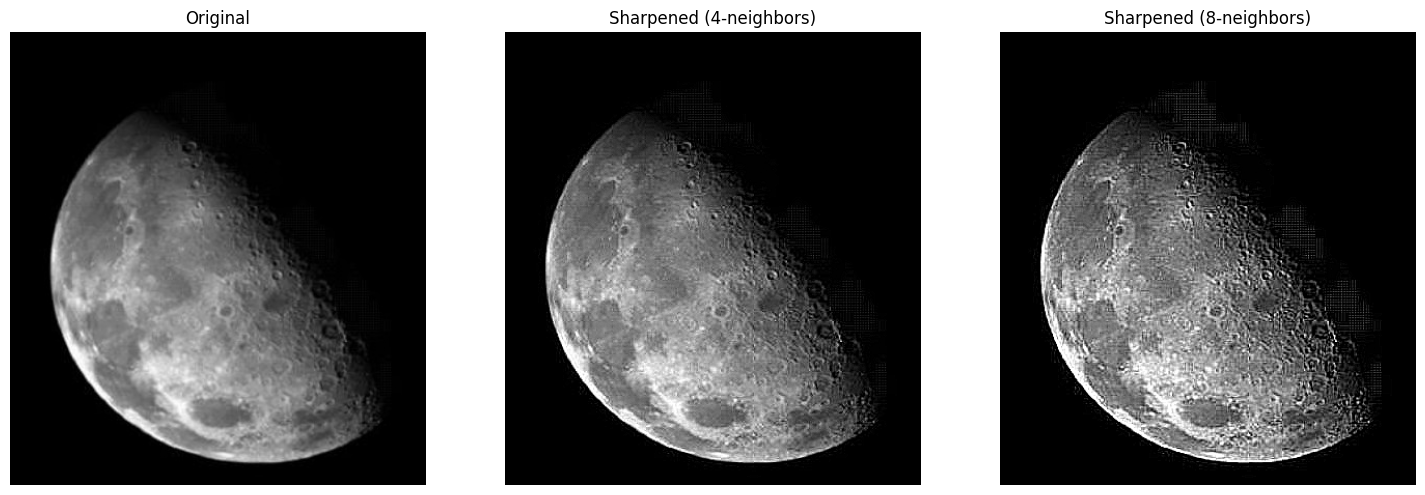

In [10]:
kernel8 = np.array([
    [1,  1, 1],
    [1, -8, 1],
    [1,  1, 1]
], dtype=np.float32)

lap8 = cv2.filter2D(img, cv2.CV_64F, kernel8)
sharp8 = np.clip(img.astype(np.float64) - lap8, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(132), plt.imshow(sharp, cmap='gray'), plt.title('Sharpened (4-neighbors)'), plt.axis('off')
plt.subplot(133), plt.imshow(sharp8, cmap='gray'), plt.title('Sharpened (8-neighbors)'), plt.axis('off')
plt.tight_layout(); plt.show()

## 3) Built-in `cv2.Laplacian` (with Gaussian Blur to reduce noise)

The Laplacian is very sensitive to noise (second derivative), so we smooth the image first. `cv2.Laplacian` with `ksize=1` uses the same kernel (0,1,0 / 1,-4,1 / 0,1,0), so the combination is again a subtraction.

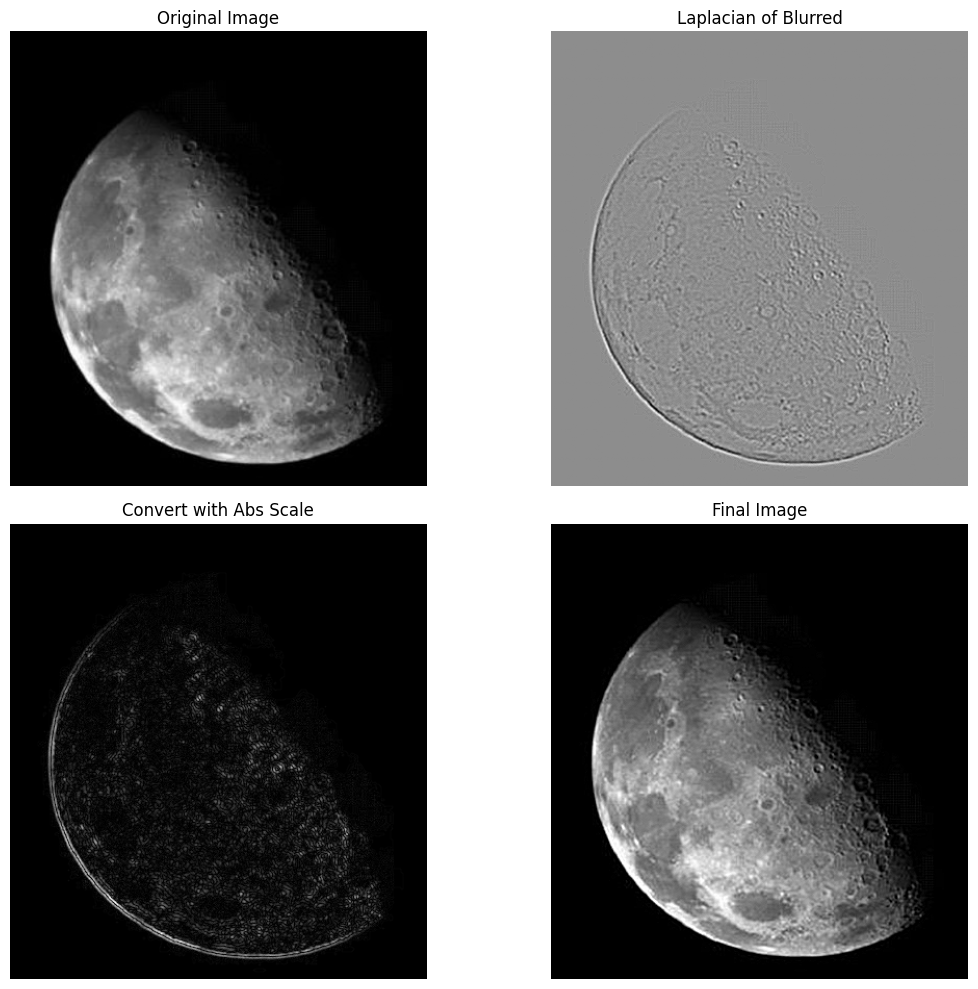

In [11]:
blurred = cv2.GaussianBlur(img, (3, 3), 0)

laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=1)
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# Combine with the original image (subtract because the kernel center is negative)
final2 = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image'), plt.axis('off')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian of Blurred'), plt.axis('off')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale'), plt.axis('off')
plt.subplot(224), plt.imshow(final2, cmap='gray'), plt.title('Final Image'), plt.axis('off')
plt.tight_layout(); plt.show()

## 4) Sharpening Strength and the Overflow Bug

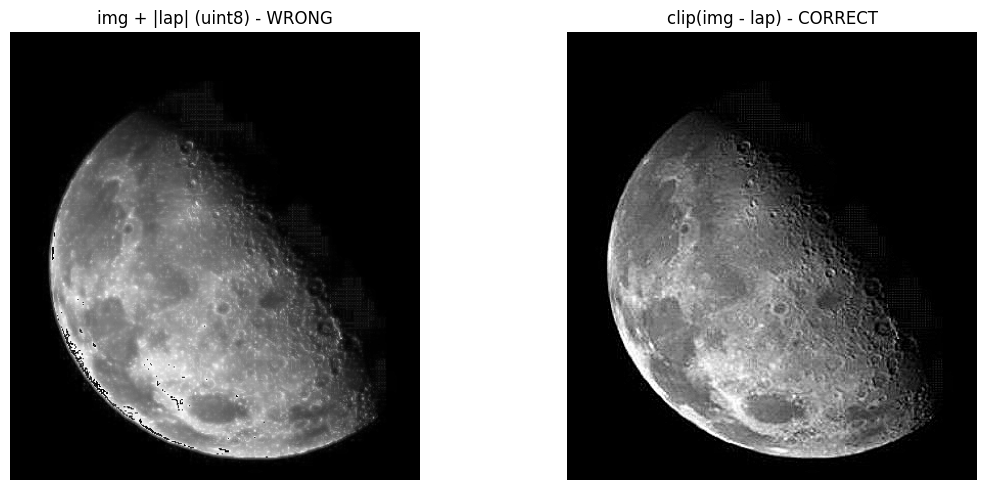

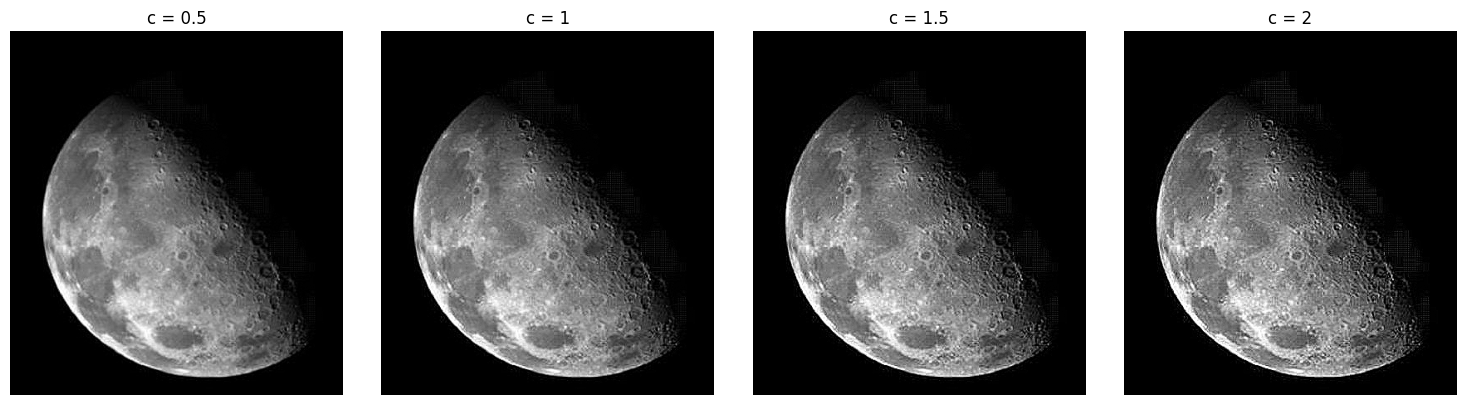

In [12]:
# Wrong way (uint8 wrap-around) vs. correct way
wrong = img + lap_abs          # overflow on uint8
right = sharp

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(wrong, cmap='gray'), plt.title('img + |lap| (uint8) - WRONG'), plt.axis('off')
plt.subplot(122), plt.imshow(right, cmap='gray'), plt.title('clip(img - lap) - CORRECT'), plt.axis('off')
plt.tight_layout(); plt.show()

# Control sharpening strength: g = f - c * Laplacian
plt.figure(figsize=(15, 4))
for i, c in enumerate([0.5, 1, 1.5, 2]):
    g = np.clip(img.astype(np.float64) - c * lap, 0, 255).astype(np.uint8)
    plt.subplot(1, 4, i+1), plt.imshow(g, cmap='gray'), plt.title(f'c = {c}'), plt.axis('off')
plt.tight_layout(); plt.show()

## Summary
- Laplacian = second derivative: it highlights edges and fine details (moon craters) and ignores uniform regions.
- The 8-neighbors kernel gives stronger edges because it includes diagonal directions.
- Combination: negative center => `f - ∇²f`, positive center => `f + ∇²f`.
- Compute in `float64` then `clip` to avoid overflow.
- It is noise-sensitive, so apply a Gaussian Blur first when needed.